In [ ]:
!pip install torch torchvision torchaudio
!pip install scikit-learn seaborn tqdm matplotlib


In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/Domain Adaptation


/content/drive/MyDrive/Colab Notebooks/Domain Adaptation


In [ ]:
SOURCE = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged"
TARGET = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled/dummy"
TEST   = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"

In [ ]:
!python attention_dann_mobilenetv2_ep2.py \
  --source-dir "$SOURCE" \
  --target-dir "$TARGET" \
  --test-dir "$TEST" \
  --out-dir /content/drive/MyDrive/Colab\ Results/DANN_GLOBAL_ATTN \
  --epochs 30 \
  --iters-per-epoch 300 \
  --batch-size 16 \
  --lambda-val 1.0 \
  --gamma 0.02 \
  --use-tada \
  --lr 1e-4 \
  --device cuda


Loading datasets...
Building model...
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth
100% 13.6M/13.6M [00:00<00:00, 211MB/s]
Training DANN (+ TADA=True)...
DANN+TADA Train Ep 1/30: 100% 300/300 [19:13<00:00,  3.85s/it, cls=0.699, dom_global=0.997, dom_local=0, ent=0, loss=1.7]
DANN+TADA Train Ep 2/30: 100% 300/300 [18:51<00:00,  3.77s/it, cls=0.803, dom_global=0.603, dom_local=0, ent=0, loss=1.41]
DANN+TADA Train Ep 3/30: 100% 300/300 [18:27<00:00,  3.69s/it, cls=1.47, dom_global=0.644, dom_local=0, ent=0, loss=2.11]
DANN+TADA Train Ep 4/30: 100% 300/300 [18:28<00:00,  3.70s/it, cls=1.19, dom_global=0.685, dom_local=0, ent=0, loss=1.87]
DANN+TADA Train Ep 5/30: 100% 300/300 [18:43<00:00,  3.75s/it, cls=0.861, dom_global=0.681, dom_local=0, ent=0, loss=1.54]
DANN+TADA Train Ep 6/30: 100% 300/300 [04:28<00:00,  1.12it/s, cls=0.96, dom_global=0.572, dom_local=0, ent=0, loss=1.53]
DANN+TADA Train 

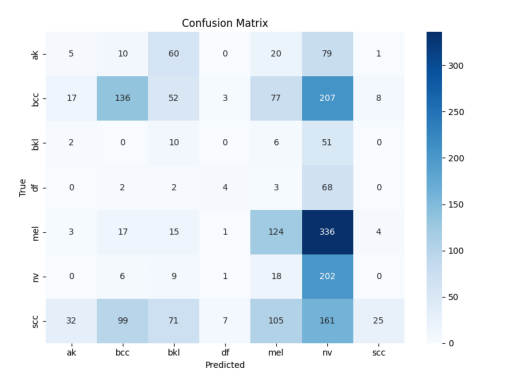

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread('/content/drive/MyDrive/Colab Results/DANN_GLOBAL_ATTN/confusion_matrix.png')
plt.imshow(img)
plt.axis('off')
plt.show()


In [ ]:
import pandas as pd
report = pd.read_csv('/content/drive/MyDrive/Colab Results/DANN_GLOBAL_ATTN/classification_report.csv', index_col=0)
report


,precision,recall,f1-score,support
ak,0.084746,0.028571,0.042735,175.00000
bcc,0.503704,0.272000,0.353247,500.00000
bkl,0.045662,0.144928,0.069444,69.00000
df,0.250000,0.050633,0.084211,79.00000
mel,0.351275,0.248000,0.290739,500.00000
nv,0.182971,0.855932,0.301493,236.00000
scc,0.657895,0.050000,0.092937,500.00000
accuracy,0.245750,0.245750,0.245750,0.24575
macro avg,0.296607,0.235723,0.176401,2059.00000
weighted avg,0.406677,0.245750,0.222699,2059.00000


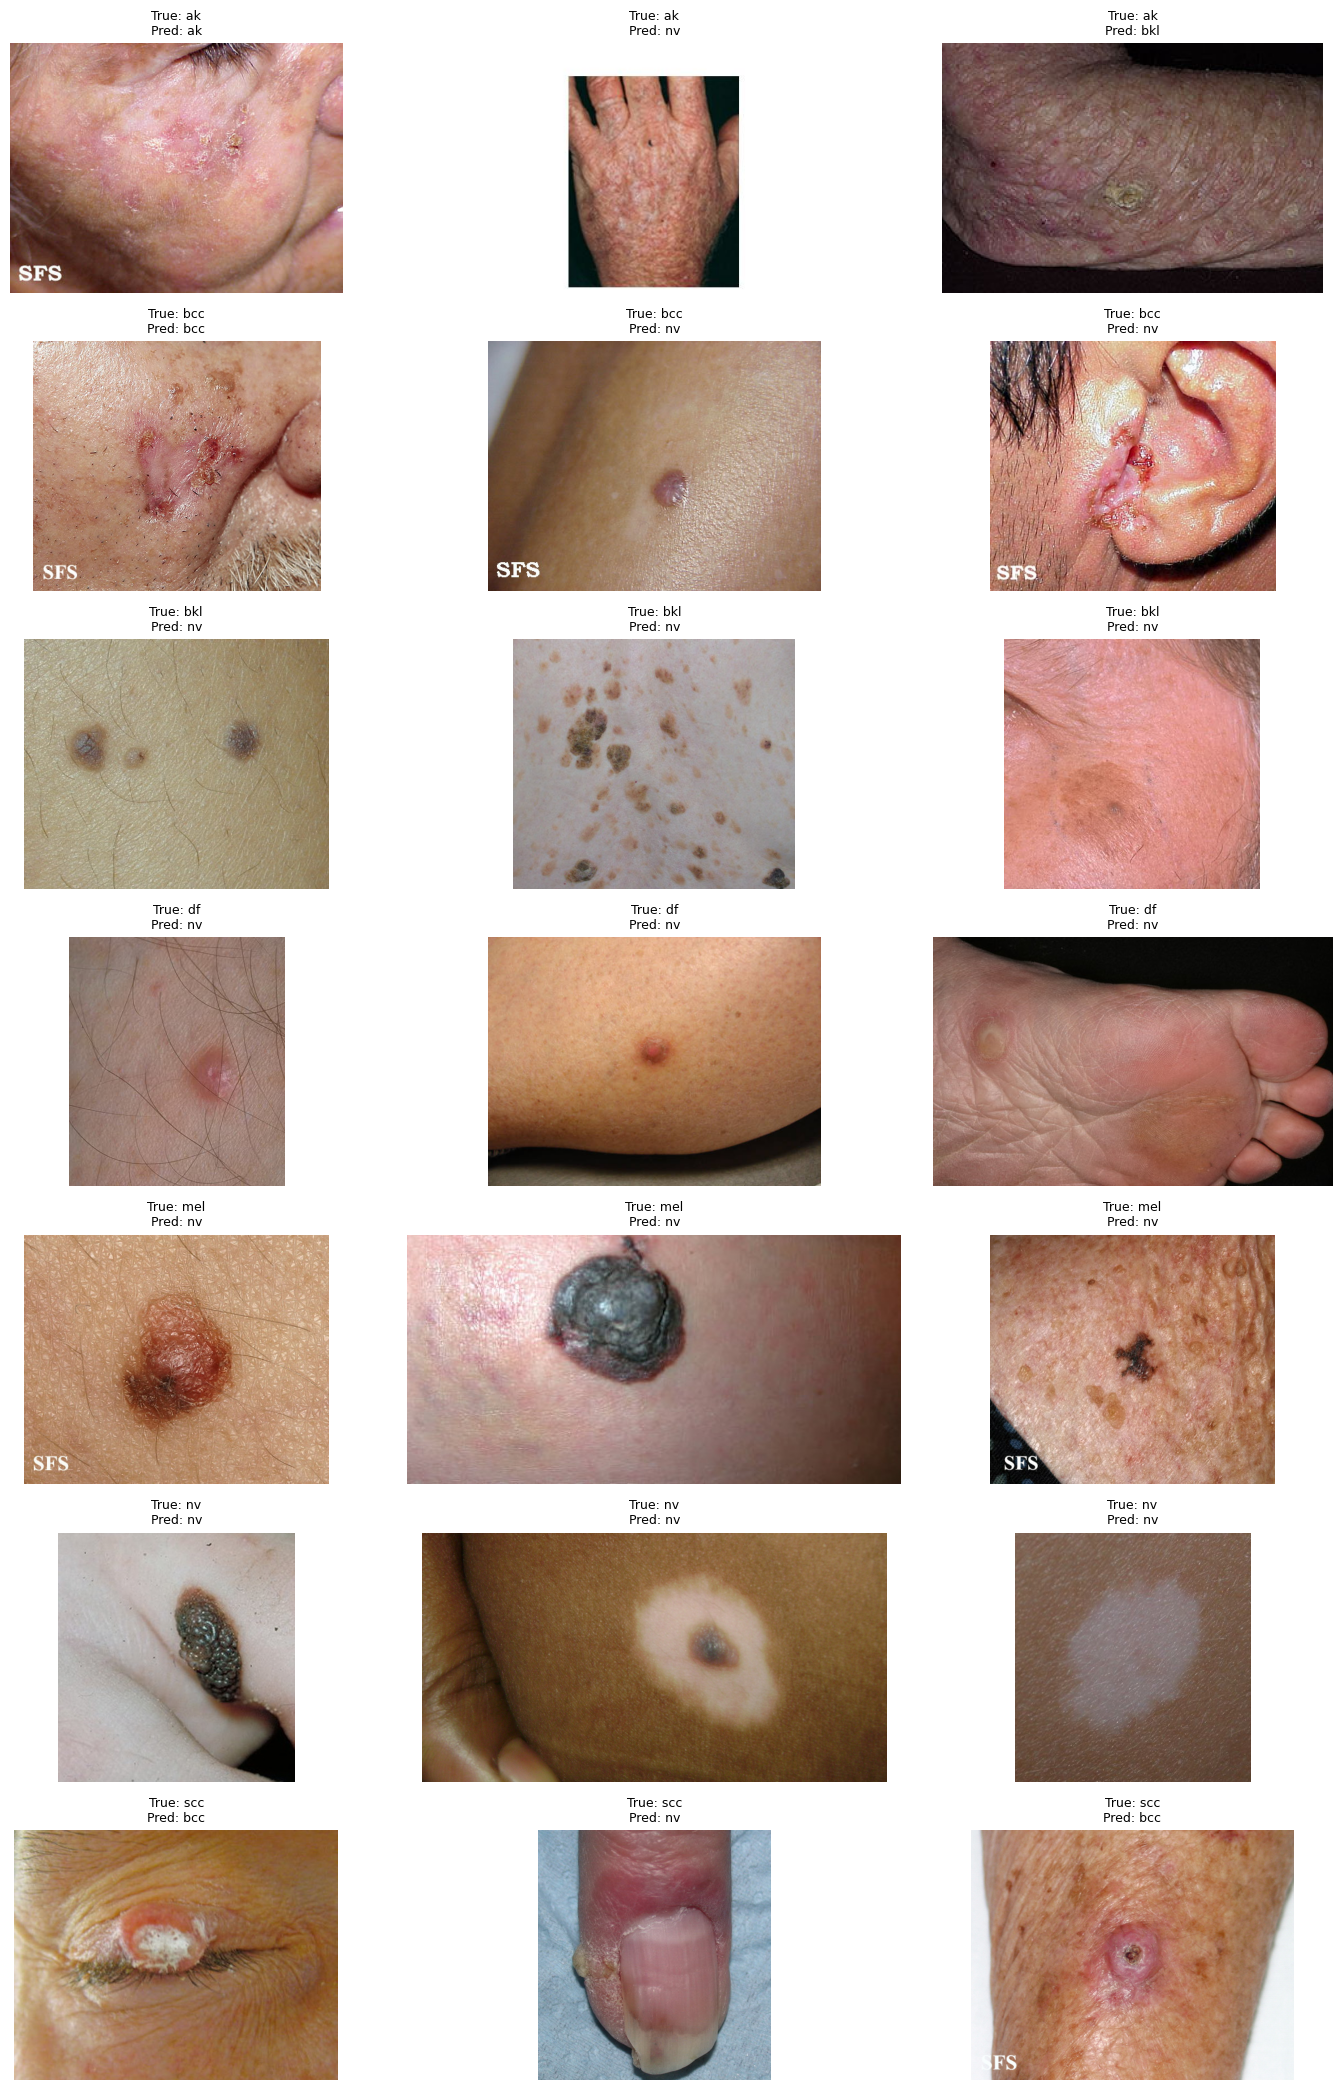

In [ ]:
import os
import torch
import random
import matplotlib.pyplot as plt
import numpy as np
from torchvision import transforms
from PIL import Image

# ---- Paths ----
TEST_DIR = TEST  # reuse your test path from earlier
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# ---- Load model ----
from attention_dann_mobilenetv2 import get_mobilenetv2_encoder, ClassifierHead

encoder, feat_dim = get_mobilenetv2_encoder(pretrained=False)
classifier = ClassifierHead(feat_dim, num_classes=7)

checkpoint = torch.load('/content/drive/MyDrive/Colab Results/DANN_GLOBAL_ATTN/full_model.pth', map_location=device)
encoder.load_state_dict(checkpoint['encoder'])
classifier.load_state_dict(checkpoint['classifier'])
encoder.to(device).eval()
classifier.to(device).eval()

# ---- Prepare transform ----
tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# ---- Get class folders ----
class_dirs = [os.path.join(TEST_DIR, c) for c in os.listdir(TEST_DIR) if os.path.isdir(os.path.join(TEST_DIR, c))]
class_dirs.sort()
classes = [os.path.basename(c) for c in class_dirs]

# ---- Predict samples ----
num_samples = 3  # how many per class
plt.figure(figsize=(15, len(classes)*3))

for i, (cls, cls_dir) in enumerate(zip(classes, class_dirs)):
    images = random.sample([os.path.join(cls_dir, x) for x in os.listdir(cls_dir) if x.endswith(('.jpg','.png','.jpeg'))], num_samples)

    for j, img_path in enumerate(images):
        img = Image.open(img_path).convert("RGB")
        inp = tfm(img).unsqueeze(0).to(device)
        with torch.no_grad():
            fmap, pooled = encoder(inp)
            pred = classifier(pooled).argmax(1).item()

        plt.subplot(len(classes), num_samples, i*num_samples + j + 1)
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"True: {cls}\nPred: {classes[pred]}", fontsize=9)

plt.tight_layout()
plt.show()
